In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
x = np.array([-1.0, 0.0, 1.0, 2.0])
y = 2 * x + 1

print("x:", x)
print("y:", y)

x: [-1.  0.  1.  2.]
y: [-1.  1.  3.  5.]


In [3]:
w = 0.0
b = 0.0

def forward(x, w, b):
    return w * x + b

def mse(y_pred, y):
    return np.mean((y_pred - y) ** 2)

y_pred = forward(x, w, b)
loss = mse(y_pred, y)

print("Prediction:", y_pred)
print("Loss:", loss)

Prediction: [0. 0. 0. 0.]
Loss: 9.0


In [4]:
def gradients(x, y, w, b):
    y_pred = forward(x, w, b)
    error = y_pred - y

    dw = 2 * np.mean(error * x)
    db = 2 * np.mean(error)

    return dw, db

dw, db = gradients(x, y, w, b)

print("dw:", dw)
print("db:", db)

dw: -7.0
db: -4.0


In [7]:
def train(lr, epochs=80):
    w = 0.0
    b = 0.0
    losses = []

    for epoch in range(epochs):
        y_pred = forward(x, w, b)
        loss = mse(y_pred, y)
        losses.append(loss)

        dw, db = gradients(x, y, w, b)

        w -= lr * dw
        b -= lr * db

    return w, b, losses

lr=0.01: w=1.8660, b=0.9947
lr=0.1: w=2.0000, b=1.0000
lr=1.0: w=-5193981023518024674213095964409856.0000, b=-3210056809456106388978201849233408.0000


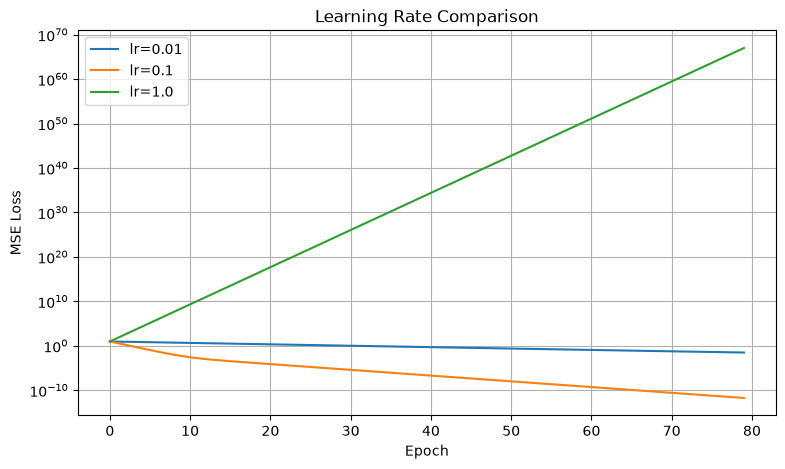

In [8]:
learning_rates = [0.01, 0.1, 1.0]

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    w, b, losses = train(lr)

    print(f"lr={lr}: w={w:.4f}, b={b:.4f}")
    plt.plot(losses, label=f"lr={lr}")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Learning Rate Comparison")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()